# 03 · Subsurface marine heatwaves (4-D)

Marine heatwaves are usually studied at the surface, but many start, persist or
only exist below it (Sun et al. 2023; Köhn et al. 2024; Malan et al., 2025). This notebook runs xrMHW on
temperature over time, depth, latitude and longitude, and shows ways to look at the
result: vertical profiles, a depth–time diagram, sections across the shelf edge,
how often events are hidden below the surface, and a 3-D view.

The data are GLORYS12V1 potential temperature from 1993 to 2025 on 33 levels down
to 644 m, in a 12 × 12 window that crosses the edge of the Grand Bank of
Newfoundland: shallow shelf to the west, the continental slope to the east. The
window is small, and the figures below illustrate the methods; they are not a
regional analysis.

In [1]:
import time

import cmocean
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pooch
import xarray as xr
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.patches import Patch

import xrMHW

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 11, "axes.titleweight": "bold", "font.size": 9,
})
INK, INK2 = "#0b0b0b", "#52514e"
BLUE, ORANGE = "#2a78d6", "#eb6834"
SEAFLOOR = "#bdbbb4"
CAT_COLORS = ["#d3957f", "#c0583b", "#9d1926", "#5c0e21"]
CAT_NAMES = ["Moderate", "Strong", "Severe", "Extreme"]
CAT_CMAP = ListedColormap(CAT_COLORS)
CAT_NORM = BoundaryNorm([1, 2, 3, 4, 5], CAT_CMAP.N)


def depth_axis(ax, zmax=650):
    """Depth downwards, linear in the upper 20 m and logarithmic below."""
    ax.set_yscale("symlog", linthresh=20)
    ticks = [0, 10, 20, 50, 100, 200, 400, 600]
    ax.set_yticks(ticks, [str(t) for t in ticks])
    ax.set_ylim(zmax, 0)
    ax.set_ylabel("depth (m)")


def category_legend(ax, **kw):
    """Legend of the four severity bands used by every severity plot below."""
    handles = [Patch(color=c, label=f"{n} ({i + 1}–{i + 2})" if i < 3 else f"{n} (≥4)")
               for i, (c, n) in enumerate(zip(CAT_COLORS, CAT_NAMES))]
    ax.legend(handles=handles, title="severity", frameon=False, **kw)


EXAMPLE_DATA = pooch.create(
    path=pooch.os_cache("xrmhw"),
    base_url="doi:10.5281/zenodo.22909109/",
    registry={
        "xrmhw_glorys_4d_subset.nc": "md5:5555737e45f1c6cde9f657e50f456693",
        "xrmhw_ostia_sst_3d.nc": "md5:74a2da227394e4463f203f6b388518ee",
    },
)
glorys = xr.open_dataset(EXAMPLE_DATA.fetch("xrmhw_glorys_4d_subset.nc"))

## 1. Prepare the input and estimate the memory

The file stores 16-bit integers that xarray unpacks to 64-bit floats. Casting to
32-bit floats halves the memory and loses nothing: the packing resolution is
0.0007 °C.

In our benchmarks, the peak memory of an in-memory run was about **7.25 times** the
size of the decoded input, because the input, the climatology, the threshold and the
outputs coexist. Chunking lets Dask work on a few pieces at a time, so the peak then
depends on the chunk size, not on the whole dataset. Here chunks of three depth
levels keep each piece small.

In [2]:
ds = glorys[["thetao"]].astype("float32")
gib = ds["thetao"].nbytes / 2**30
print(f"decoded input {gib:.2f} GiB -> roughly {7.25 * gib:.1f} GiB if run all in memory")
ds = ds.chunk({"time": -1, "depth": 3, "latitude": -1, "longitude": -1})
print(f"{ds['thetao'].data.npartitions} chunks of "
      f"{np.prod(ds['thetao'].data.chunksize) * 4 / 2**20:.0f} MiB")

decoded input 0.21 GiB -> roughly 1.5 GiB if run all in memory
11 chunks of 20 MiB


## 2. Run the detection

The call is the same as for one time series. Every cell of every level gets its own
climatology and threshold over 1993–2022. Cells below the sea floor are missing
for the whole record and are skipped.

In [4]:
CLIM = (1993, 2022)
t0 = time.perf_counter()
out = xrMHW.xrMHW_func(ds, "thetao", clim_period=CLIM,
                       output_vars=["intensity", "severity", "category"]).compute()
print(f"detection over {ds['thetao'].size / 1e6:.0f} million values in "
      f"{time.perf_counter() - t0:.0f} s")

valid = glorys["thetao"].isel(time=0).notnull()       # water, not sea floor
in_mhw = out["mhw_severity"].notnull()

detection over 57 million values in 23 s


## 3. Why severity, not intensity, to compare depths

Take the offshore column on one day of an event, 16 January 2025. The left panel
shows the anomaly in °C. The middle panel shows the distance between the threshold
and the climatology, a measure of how much temperature usually varies at each depth.
Severity divides one by the other (right panel). Because the usual variability
changes with depth, anomalies in °C at different depths are not directly
comparable; severity puts them on one scale.

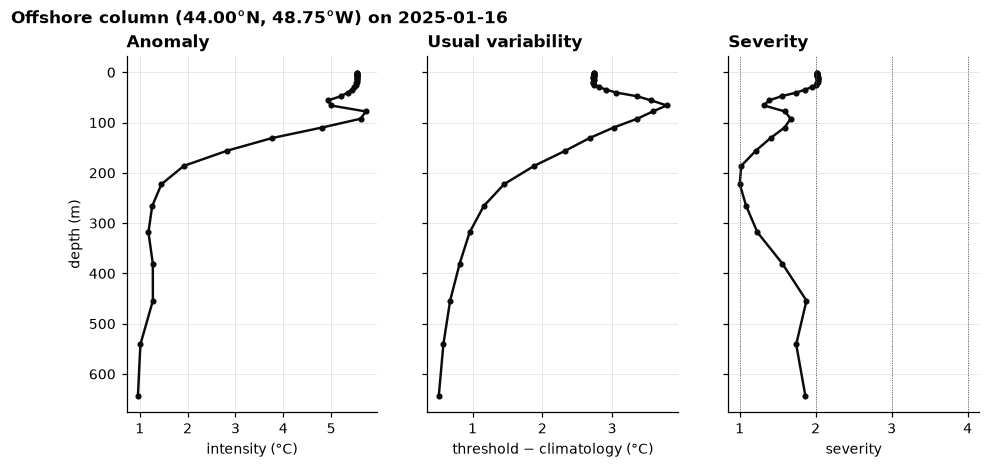

In [6]:
col = dict(latitude=44.0, longitude=-48.75)
column = glorys.sel(**col, method="nearest")[["thetao"]].load()
col_clim = xrMHW.xrMHW_func(column, "thetao", clim_period=CLIM,
                            output_vars=["climatology", "threshold"])
day = "2025-01-16"
spread = (col_clim["mhw_threshold"] - col_clim["climatology"]).sel(time=day)
prof = out.sel(**col, method="nearest").sel(time=day)

fig, axes = plt.subplots(1, 3, figsize=(10, 4.2), sharey=True)
panels = [(prof["mhw_intensity"], "intensity (°C)", "Anomaly"),
          (spread, "threshold − climatology (°C)", "Usual variability"),
          (prof["mhw_severity"], "severity", "Severity")]
for ax, (x, label, title) in zip(axes, panels):
    ax.plot(x, glorys.depth, color=INK, lw=1.6, marker="o", ms=3)
    ax.set_xlabel(label)
    ax.set_title(title, loc="left")
    ax.grid(color="#e7e6e2", lw=0.6)
for k in (1, 2, 3, 4):
    axes[2].axvline(k, color=INK2, lw=0.6, ls=":")
axes[0].set_ylabel("depth (m)")
axes[0].invert_yaxis()
fig.suptitle(f"Offshore column ({float(column.latitude):.2f}°N, "
             f"{-float(column.longitude):.2f}°W) on {day}", x=0.02, ha="left",
             fontweight="bold")
plt.show()

## 4. Depth–time diagram of one column

A Hovmöller diagram shows when events occur at each depth. The colour bands are the
severity categories; white means no marine heatwave.

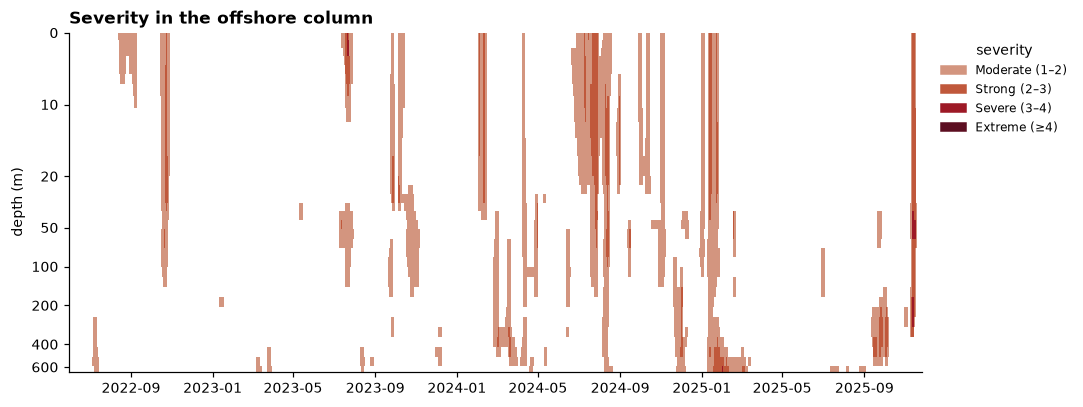

In [7]:
sev_col = out["mhw_severity"].sel(**col, method="nearest").sel(time=slice("2022-06", "2025-11"))
fig, ax = plt.subplots(figsize=(10, 4))
m = ax.pcolormesh(sev_col.time, sev_col.depth, sev_col.transpose("depth", "time").clip(max=4.99),
                  cmap=CAT_CMAP, norm=CAT_NORM, shading="nearest")
depth_axis(ax)
ax.set_title("Severity in the offshore column", loc="left")
category_legend(ax, loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)
plt.show()

The depth axis is stretched near the surface (linear above 20 m, logarithmic below)
so that thin surface events remain visible.

## 5. Sections across the shelf edge

A section along one latitude cuts from the shelf (west) to the slope (east). Grey is
the sea floor as the model resolves it. The section is drawn for two dates, one in
winter and one in summer.

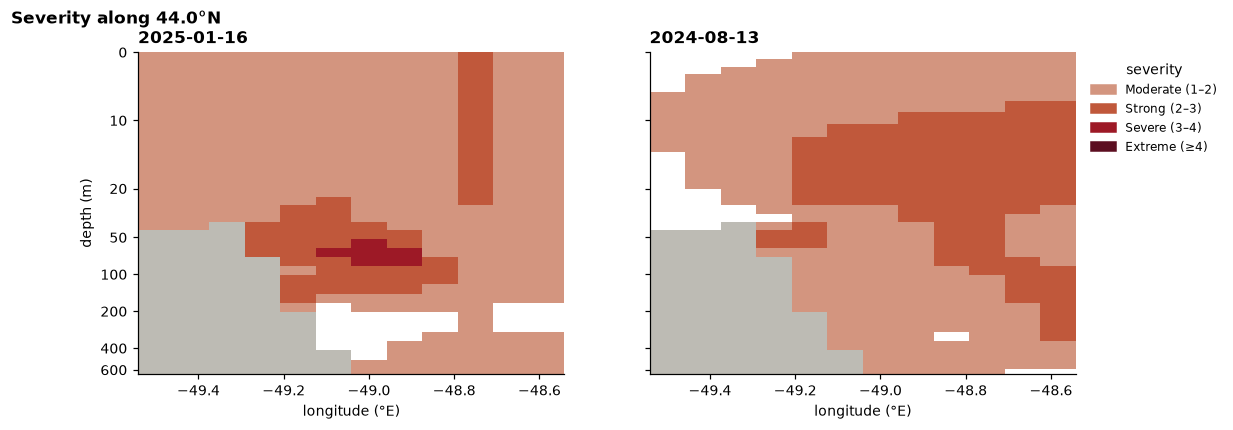

In [8]:
lat_row = 44.0
dates = ["2025-01-16", "2024-08-13"]
floor = ~valid.sel(latitude=lat_row, method="nearest")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, d in zip(axes, dates):
    sec = out["mhw_severity"].sel(latitude=lat_row, method="nearest").sel(time=d)
    ax.pcolormesh(sec.longitude, sec.depth, sec.transpose("depth", "longitude").clip(max=4.99), cmap=CAT_CMAP,
                  norm=CAT_NORM, shading="nearest")
    ax.pcolormesh(floor.longitude, floor.depth, floor.where(floor), cmap=ListedColormap([SEAFLOOR]),
                  shading="nearest")
    depth_axis(ax)
    ax.set_title(f"{d}", loc="left")
    ax.set_xlabel("longitude (°E)")
axes[1].set_ylabel("")
category_legend(axes[1], loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)
fig.suptitle(f"Severity along {lat_row}°N", x=0.02, ha="left", fontweight="bold")
plt.show()

## 6. Hidden below the surface

How often is a cell in a marine heatwave while the surface above it is not? For
each level, the left panel gives the share of days in a marine heatwave and the
right panel the part of those days on which the surface of the same column was not
in one.

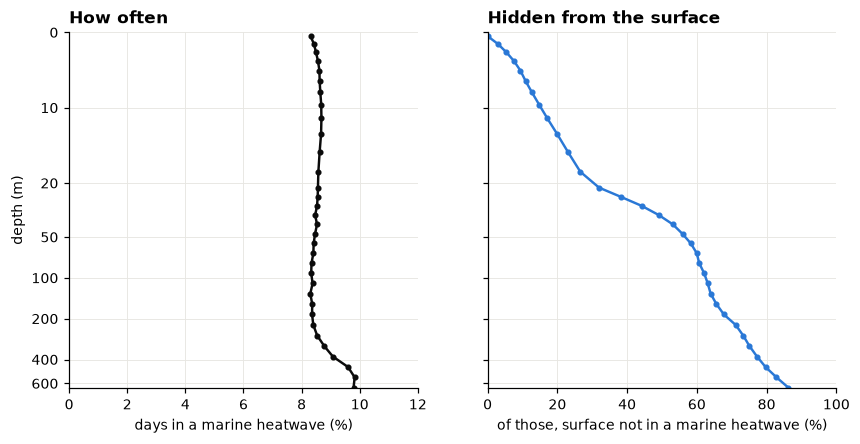

In [9]:
surface_mhw = in_mhw.isel(depth=0)
hidden = in_mhw & ~surface_mhw
share_mhw = in_mhw.where(valid).mean(("time", "latitude", "longitude"))
share_hidden = hidden.where(valid).sum(("time", "latitude", "longitude")) / \
    in_mhw.where(valid).sum(("time", "latitude", "longitude"))

fig, axes = plt.subplots(1, 2, figsize=(9, 4.2), sharey=True)
axes[0].plot(100 * share_mhw, glorys.depth, color=INK, lw=1.6, marker="o", ms=3)
axes[0].set_xlabel("days in a marine heatwave (%)")
axes[0].set_xlim(0, 12)
axes[1].plot(100 * share_hidden, glorys.depth, color=BLUE, lw=1.6, marker="o", ms=3)
axes[1].set_xlabel("of those, surface not in a marine heatwave (%)")
axes[1].set_xlim(0, 100)
for ax in axes:
    depth_axis(ax)
    ax.grid(color="#e7e6e2", lw=0.6)
axes[1].set_ylabel("")
axes[0].set_title("How often", loc="left")
axes[1].set_title("Hidden from the surface", loc="left")
plt.show()

These shares depend on the window, the period and the baseline. Here they only
illustrate the calculation, which takes a few lines on any 4-D output of xrMHW.

## 7. A 3-D view

An interactive plotly figure shows every cell in a marine heatwave on one day,
coloured by category. Rotate and zoom it in Jupyter. Interactive figures do not
display on GitHub, so a static version follows.

In [10]:
import plotly.graph_objects as go

snap = out["mhw_severity"].sel(time=day)
pts = snap.where(snap.notnull(), drop=True).to_dataframe().dropna().reset_index()
pts["category"] = np.clip(np.floor(pts["mhw_severity"]), 1, 4).astype(int)

fig3d = go.Figure()
for k in range(1, 5):
    p = pts[pts.category == k]
    fig3d.add_trace(go.Scatter3d(
        x=p.longitude, y=p.latitude, z=-p.depth, mode="markers", name=CAT_NAMES[k - 1],
        marker=dict(size=3, color=CAT_COLORS[k - 1]),
        hovertemplate="%{y:.2f}°N %{x:.2f}°E, %{z:.0f} m<br>severity %{customdata:.2f}",
        customdata=p.mhw_severity))
fig3d.update_layout(
    title=f"Cells in a marine heatwave on {day}", height=520,
    scene=dict(xaxis_title="longitude", yaxis_title="latitude", zaxis_title="depth (m)",
               aspectmode="manual", aspectratio=dict(x=1, y=1, z=0.8)),
    legend=dict(title="category"), margin=dict(l=0, r=0, t=40, b=0))
fig3d.show()

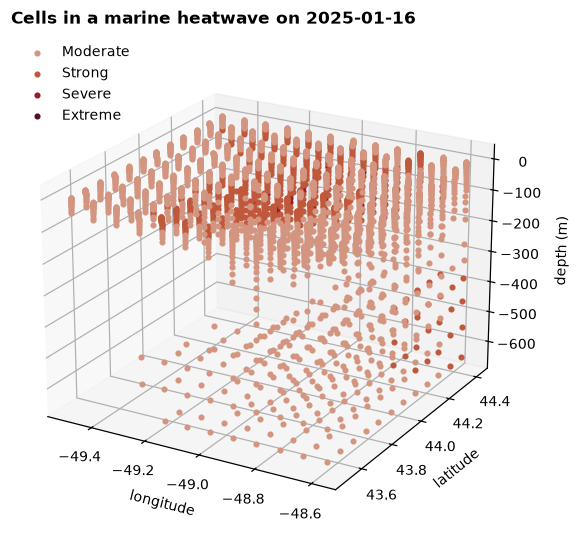

In [11]:
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection="3d")
for k in range(1, 5):
    p = pts[pts.category == k]
    ax.scatter(p.longitude, p.latitude, -p.depth, s=9, color=CAT_COLORS[k - 1],
               label=CAT_NAMES[k - 1], depthshade=False)
ax.set_xlabel("longitude")
ax.set_ylabel("latitude")
ax.set_zlabel("depth (m)", labelpad=8)
ax.view_init(elev=22, azim=-60)
ax.set_title(f"Cells in a marine heatwave on {day}", loc="left")
ax.legend(frameon=False, loc="upper left")
plt.show()

## 8. What these results are, and what they are not

Everything above is built from **pointwise** detections: each cell was analysed
alone, and a coloured cell means that cell was in a marine heatwave. Neighbouring
cells that are in an event at the same time are not linked into one object, and
`mhw_duration` is the persistence at each cell, not the lifetime of a 3-D structure.
To follow events as objects (their volume, the depth they reach, how they move),
pass the event mask or severity to a tracking method, such as Ocetrac (only designed for surface data) (Scannell et al. 2024; Cai et al. 2025) in two dimensions or a connected-component labelling in three.

## Summary

- The 4-D call is the same as the 1-D call; chunk over depth or space and keep time
  whole.
- Use severity to compare depths: it normalises the anomaly by the local
  variability, which changes with depth.
- Masks such as "in a marine heatwave below, but not at the surface" take a few
  lines of xarray on the output.

Next: **04 · Many files, Dask and Zarr**, for datasets that do not fit in memory.

### References

- Köhn, E. E., et al. (2024). On the vertical structure and propagation of marine heatwaves in the Eastern Pacific. *Journal of Geophysical Research: Oceans*, 129, e2023JC020063. https://doi.org/10.1029/2023JC020063
- Sun, D., et al. (2023). Frequent marine heatwaves hidden below the surface of the global ocean. *Nature Geoscience*, 16, 1099–1104. https://doi.org/10.1038/s41561-023-01325-w
- Scannell, H. A., et al. (2024). Spatiotemporal evolution of marine heatwaves globally. *Journal of Atmospheric and Oceanic Technology*, 41(12), 1247–1263. https://doi.org/10.1175/JTECH-D-23-0126.1
- Cai, C., et al. (2025). Ocetrac: An object-based framework for tracking and quantifying climate events in gridded datasets. In *Proceedings of the 24th Python in Science Conference* (pp. 54–66). https://doi.org/10.25080/vxkf4244
- Data: E.U. Copernicus Marine Service Information, https://doi.org/10.48670/moi-00021